# Ascoli Lab Sloppy/Stiff Parameter Analysis

This notebook uses the supplied Ascoli Lab CSV files to analyze stiffness and sloppiness for:

- `q_i`
- `c_ij`
- `G_ij = g_ij * v_ij`, where `v_ij` is the provided voltage term
- `tau_ij`, using `tau_d`
- `k_j`, using `85_kj.csv` with `mij_netlist.csv` fallback where needed

The default observable is:

```text
m_ij = q_i * c_ij * G_ij * tau_ij * k_j
```

The analysis works in log-parameter coordinates. It uses an analytic sensitivity matrix rather than finite differences because the provided model is multiplicative.

## tl;dr

Run all cells to produce:

- `ascoli_mode_table.csv`: sensitivity-ranked stiff/sloppy modes;
- `ascoli_parameter_scores.csv`: parameter-level stiff/sloppy participation;
- `ascoli_kj_sensitivity_scores.csv`: focused `k_j` sensitivity results;
- `ascoli_family_summary.csv`: summary by parameter family.

Interpret stiff/sloppy first as coordinated eigendirections. Individual parameters are best described as stiff-associated or sloppy-associated based on their participation in those directions.

## Context & Methods

A log transform converts the product into an additive expression:

```text
log |m_ij| =
    log q_i + log c_ij + log |G_ij| + log tau_ij + log k_j
```

This makes multiplicative parameters comparable, but it does not remove degeneracy. If the data only constrain the product, many compensating log-parameter changes can leave `m_ij` unchanged. The Fisher/SVD analysis below identifies those stiff and sloppy combinations.

The default sensitivity scaling is relative: each edge output is divided by `abs(m_ij)`. This asks which parameters affect fractional changes in `m_ij`. Switch to absolute scaling if large-magnitude edges should dominate.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 30)
np.set_printoptions(precision=4, suppress=True)

OUTPUT_DIR = Path(r"C:\Users\ranic\Documents\Codex\2026-10-08\develop-a-workflow-or-ipynb-that-2\outputs")
EDGE_TABLE_PATH = OUTPUT_DIR / "ascoli_edge_product_table.csv"
PARAMETER_TABLE_PATH = OUTPUT_DIR / "ascoli_parameter_table.csv"
AUDIT_PATH = OUTPUT_DIR / "ascoli_parameter_source_audit.csv"

STIFF_CUMULATIVE_FRACTION = 0.95
SLOPPY_RELATIVE_EIGENVALUE = 1e-6
SCALE_MODE = "relative"  # "relative" or "absolute"

## Data

In [2]:
edge_table = pd.read_csv(EDGE_TABLE_PATH)
parameter_table = pd.read_csv(PARAMETER_TABLE_PATH)
audit = pd.read_csv(AUDIT_PATH)

display(audit)
display(edge_table.head())
display(parameter_table.head())

,check,value
0,kj_rows,8.500000e+01
1,edge_rows,1.641000e+03
2,parameter_rows,5.093000e+03
3,missing_q_i_edges,0.000000e+00
4,missing_k_j_edges_after_fallback,0.000000e+00
5,k_j_edges_using_mij_fallback,1.300000e+01
6,max_abs_w_ij_diff_vs_source,4.656613e-10
7,max_abs_m_ij_diff_vs_source,5.820766e-11
8,mean_abs_m_ij_diff_vs_source,3.698750e-13


,pre_neuron_id,post_neuron_id,pre_neuron,post_neuron,pre_neuron_canonical,post_neuron_canonical,pre_ei,post_ei,c_ij,g_ij,v_ij,tau_d,q_i,k_j_file_neuron_type,k_j_file,w_ij_source,k_j_mij_source,m_ij_source,k_j,k_j_source,G_ij,w_ij_calc,m_ij_calc,w_ij_abs_diff,m_ij_abs_diff
0,1000,1002,DG Granule,DG Mossy,DG Granule,DG Mossy,e,e,0.007771,1.490,62.0,5.468,394502.0,DG Mossy,0.02900,1.548576e+06,0.02900,44908.709979,0.02900,85_kj.csv,92.3800,1.548576e+06,44908.709979,0.0,0.0
1,1000,1004,DG Granule,DG Total Molecular Layer,DG Granule,DG Total Molecular Layer,e,i,0.004220,1.376,54.5,4.814,394502.0,DG Total Molecular Layer,0.07440,6.010114e+05,0.07440,44715.245336,0.07440,85_kj.csv,74.9920,6.010114e+05,44715.245336,0.0,0.0
2,1000,1005,DG Granule,DG MOLAX,DG Granule,DG MOLAX,e,i,0.004358,1.358,54.5,4.929,394502.0,DG MOLAX,0.07440,6.271790e+05,0.07440,46662.119453,0.07440,85_kj.csv,74.0110,6.271790e+05,46662.119453,0.0,0.0
3,1000,1009,DG Granule,DG HICAP,DG Granule,DG HICAP,e,i,0.003335,1.105,60.5,4.756,394502.0,DG HICAP,0.21477,4.183161e+05,0.21477,89841.741823,0.21477,85_kj.csv,66.8525,4.183161e+05,89841.741823,0.0,0.0
4,1000,1010,DG Granule,DG Axo Axonic,DG Granule,DG Axo Axonic,e,i,0.003907,1.403,65.1,5.033,394502.0,DG Axo Axonic,0.27069,7.085299e+05,0.27069,191791.971122,0.27069,85_kj.csv,91.3353,7.085299e+05,191791.971122,0.0,0.0


,parameter_index,name,family,i,j,pre_neuron,post_neuron,value,source_column
0,0,q_i::DG Granule,q_i,1000.0,NaN,DG Granule,NaN,394502.0,q_i
1,1,q_i::DG Semilunar Granule,q_i,1001.0,NaN,DG Semilunar Granule,NaN,67090.0,q_i
2,2,q_i::DG Mossy,q_i,1002.0,NaN,DG Mossy,NaN,10485.0,q_i
3,3,q_i::DG Total Molecular Layer,q_i,1004.0,NaN,DG Total Molecular Layer,NaN,3275.0,q_i
4,4,q_i::DG MOLAX,q_i,1005.0,NaN,DG MOLAX,NaN,2223.0,q_i


## Build Analytic Sensitivity Matrix

For each edge `i -> j`, the log-sensitivity of `m_ij` to its five factors is the edge value itself:

```text
d m_ij / d log q_i = m_ij
d m_ij / d log c_ij = m_ij
d m_ij / d log G_ij = m_ij
d m_ij / d log tau_ij = m_ij
d m_ij / d log k_j = m_ij
```

Under relative scaling, each nonzero entry becomes approximately `sign(m_ij)`. Under absolute scaling, large `m_ij` edges receive more weight.

In [3]:
def parameter_key(row):
    if row["family"] == "q_i":
        return ("q_i", int(row["i"]), None)
    if row["family"] == "k_j":
        return ("k_j", None, int(row["j"]))
    return (row["family"], int(row["i"]), int(row["j"]))


parameter_index = {
    parameter_key(row): int(row["parameter_index"])
    for _, row in parameter_table.iterrows()
}


def output_scale(values, mode=SCALE_MODE):
    values = np.asarray(values, dtype=float)
    if mode == "absolute":
        return np.ones_like(values)
    if mode == "relative":
        floor = np.nanmedian(np.abs(values[np.abs(values) > 0])) * 1e-12
        return np.maximum(np.abs(values), floor)
    raise ValueError("SCALE_MODE must be 'relative' or 'absolute'")


def build_log_sensitivity(edge_table, parameter_table):
    y = edge_table["m_ij_calc"].to_numpy(dtype=float)
    scale = output_scale(y)
    S = np.zeros((len(edge_table), len(parameter_table)), dtype=float)

    for edge_row, row in enumerate(edge_table.itertuples(index=False)):
        i = int(row.pre_neuron_id)
        j = int(row.post_neuron_id)
        dy = row.m_ij_calc / scale[edge_row]
        keys = [
            ("q_i", i, None),
            ("c_ij", i, j),
            ("G_ij", i, j),
            ("tau_ij", i, j),
            ("k_j", None, j),
        ]
        for key in keys:
            S[edge_row, parameter_index[key]] = dy
    return S, y, scale


S, y, y_scale = build_log_sensitivity(edge_table, parameter_table)
S.shape, np.linalg.matrix_rank(S)

((1641, 5093), np.int64(1641))

## Stiff/Sloppy Eigendirections

In [4]:
def sensitivity_svd(S):
    U, singular_values, Vt = np.linalg.svd(S, full_matrices=False)
    eigenvalues = singular_values ** 2
    return singular_values, eigenvalues, Vt


def classify_modes(eigenvalues, n_parameters):
    positive = np.maximum(eigenvalues, 0.0)
    total = positive.sum()
    cumulative = np.cumsum(positive) / total if total else np.zeros_like(positive)
    stiff_cut = int(np.searchsorted(cumulative, STIFF_CUMULATIVE_FRACTION, side="left") + 1) if total else 0

    labels = np.array(["middle"] * len(eigenvalues), dtype=object)
    labels[:stiff_cut] = "stiff"
    if len(eigenvalues) and eigenvalues[0] > 0:
        labels[eigenvalues <= eigenvalues[0] * SLOPPY_RELATIVE_EIGENVALUE] = "sloppy"

    mode_table = pd.DataFrame({
        "mode": np.arange(1, len(eigenvalues) + 1),
        "eigenvalue": eigenvalues,
        "singular_value": np.sqrt(np.maximum(eigenvalues, 0.0)),
        "log10_eigenvalue": np.log10(np.maximum(eigenvalues, 1e-300)),
        "cumulative_fraction": cumulative,
        "classification": labels,
    })
    structural_null_modes = n_parameters - int(np.linalg.matrix_rank(S))
    return mode_table, structural_null_modes


singular_values, eigenvalues, Vt = sensitivity_svd(S)
mode_table, structural_null_modes = classify_modes(eigenvalues, len(parameter_table))
print(f"Returned SVD modes: {len(mode_table):,}")
print(f"Structural null/sloppy modes not returned by compact SVD: {structural_null_modes:,}")
display(mode_table.head(20))
display(mode_table["classification"].value_counts())

Returned SVD modes: 1,641
Structural null/sloppy modes not returned by compact SVD: 3,452


,mode,eigenvalue,singular_value,log10_eigenvalue,cumulative_fraction,classification
0,1,65.018545,8.063408,1.813037,0.007924,stiff
1,2,59.099560,7.687624,1.771584,0.015127,stiff
2,3,56.888683,7.542459,1.755026,0.022061,stiff
3,4,51.249281,7.158860,1.709688,0.028307,stiff
4,5,47.636119,6.901892,1.677936,0.034112,stiff
5,6,46.284312,6.803257,1.665434,0.039753,stiff
6,7,43.968759,6.630894,1.643144,0.045112,stiff
7,8,41.353001,6.430630,1.616507,0.050152,stiff
8,9,38.936192,6.239887,1.590353,0.054898,stiff
9,10,38.761211,6.225850,1.588397,0.059622,stiff


classification
stiff     1505
middle     136
Name: count, dtype: int64

## Parameter Participation Scores

These scores answer: which individual parameters participate in the stiff modes versus the sloppy modes?

In [5]:
def parameter_participation(parameter_table, S, eigenvalues, Vt, mode_table):
    eigenvectors = Vt.T
    contributions = (eigenvectors ** 2) * eigenvalues.reshape(1, -1)
    total = contributions.sum(axis=1)
    stiff_mask = mode_table["classification"].eq("stiff").to_numpy()
    sloppy_mask = mode_table["classification"].eq("sloppy").to_numpy()

    out = parameter_table.copy()
    out["fim_diagonal"] = np.sum(S * S, axis=0)
    out["stiff_contribution"] = contributions[:, stiff_mask].sum(axis=1) if stiff_mask.any() else 0.0
    out["sloppy_contribution_returned_modes"] = contributions[:, sloppy_mask].sum(axis=1) if sloppy_mask.any() else 0.0
    out["resolved_fisher_contribution"] = total
    out["stiff_share"] = np.divide(out["stiff_contribution"], total, out=np.zeros_like(total), where=total > 0)
    out["returned_sloppy_share"] = np.divide(
        out["sloppy_contribution_returned_modes"], total, out=np.zeros_like(total), where=total > 0
    )

    out["parameter_label"] = "stiff-sensitive but structurally confounded"
    shared_factor = out["family"].isin(["q_i", "k_j"])
    edge_factor = out["family"].isin(["c_ij", "G_ij", "tau_ij"])
    out.loc[shared_factor & (out["fim_diagonal"] > 0), "parameter_label"] = "shared-factor stiff-sensitive"
    out.loc[edge_factor & (out["fim_diagonal"] > 0), "parameter_label"] = "edge-factor stiff-sensitive but product-confounded"
    out.loc[out["fim_diagonal"] <= 1e-12, "parameter_label"] = "unobservable in selected outputs"
    out.loc[out["returned_sloppy_share"] >= 0.5, "parameter_label"] = "returned-mode sloppy-associated"
    return out.sort_values("fim_diagonal", ascending=False)


parameter_scores = parameter_participation(parameter_table, S, eigenvalues, Vt, mode_table)
display(parameter_scores.head(20))

,parameter_index,name,family,i,j,pre_neuron,post_neuron,value,source_column,fim_diagonal,stiff_contribution,sloppy_contribution_returned_modes,resolved_fisher_contribution,stiff_share,returned_sloppy_share,parameter_label
16,16,q_i::CA3c Pyramidal,q_i,2004.0,NaN,CA3c Pyramidal,NaN,18090.00000,q_i,57.0,57.0,0.0,57.0,1.0,0.0,shared-factor stiff-sensitive
28,28,q_i::CA2 Pyramidal,q_i,3000.0,NaN,CA2 Pyramidal,NaN,7772.00000,q_i,55.0,55.0,0.0,55.0,1.0,0.0,shared-factor stiff-sensitive
41,41,q_i::CA1 Back Projection,q_i,4023.0,NaN,CA1 Back Projection,NaN,793.00000,q_i,53.0,53.0,0.0,53.0,1.0,0.0,shared-factor stiff-sensitive
14,14,q_i::CA3 Pyramidal,q_i,2000.0,NaN,CA3 Pyramidal,NaN,75376.00000,q_i,44.0,44.0,0.0,44.0,1.0,0.0,shared-factor stiff-sensitive
21,21,q_i::CA3 Trilaminar,q_i,2020.0,NaN,CA3 Trilaminar,NaN,868.00000,q_i,41.0,41.0,0.0,41.0,1.0,0.0,shared-factor stiff-sensitive
63,63,q_i::MEC LII Stellate,q_i,6003.0,NaN,MEC LII Stellate,NaN,4435.00000,q_i,41.0,41.0,0.0,41.0,1.0,0.0,shared-factor stiff-sensitive
120,120,k_j::CA1 Pyramidal,k_j,NaN,4000.0,NaN,CA1 Pyramidal,0.02905,85_kj.csv,36.0,36.0,0.0,36.0,1.0,0.0,shared-factor stiff-sensitive
139,139,k_j::CA1 Basket,k_j,NaN,4078.0,NaN,CA1 Basket,0.16660,85_kj.csv,35.0,35.0,0.0,35.0,1.0,0.0,shared-factor stiff-sensitive
124,124,k_j::CA1 Radial Trilaminar,k_j,NaN,4013.0,NaN,CA1 Radial Trilaminar,0.12477,85_kj.csv,35.0,35.0,0.0,35.0,1.0,0.0,shared-factor stiff-sensitive
130,130,k_j::CA1 Axo Axonic,k_j,NaN,4036.0,NaN,CA1 Axo Axonic,0.07601,85_kj.csv,35.0,35.0,0.0,35.0,1.0,0.0,shared-factor stiff-sensitive


In [6]:
family_summary = (
    parameter_scores
    .groupby("family", as_index=False)
    .agg(
        n_parameters=("name", "count"),
        median_fim_diagonal=("fim_diagonal", "median"),
        mean_fim_diagonal=("fim_diagonal", "mean"),
        mean_stiff_share=("stiff_share", "mean"),
        shared_factor_stiff_sensitive=("parameter_label", lambda s: int((s == "shared-factor stiff-sensitive").sum())),
        edge_factor_product_confounded=("parameter_label", lambda s: int((s == "edge-factor stiff-sensitive but product-confounded").sum())),
        returned_mode_sloppy_associated=("parameter_label", lambda s: int((s == "returned-mode sloppy-associated").sum())),
    )
    .sort_values("mean_fim_diagonal", ascending=False)
)
display(family_summary)

,family,n_parameters,median_fim_diagonal,mean_fim_diagonal,mean_stiff_share,shared_factor_stiff_sensitive,edge_factor_product_confounded,returned_mode_sloppy_associated
2,k_j,85,18.0,19.305882,1.000000,85,0,0
3,q_i,85,19.0,19.305882,1.000000,85,0,0
0,G_ij,1641,1.0,1.000000,0.917124,0,1641,0
1,c_ij,1641,1.0,1.000000,0.917124,0,1641,0
4,tau_ij,1641,1.0,1.000000,0.917124,0,1641,0


## Tensor-Style Family Loading View

In [7]:
family_matrix = pd.DataFrame({
    family: (Vt[:, parameter_table["family"].eq(family).to_numpy()] ** 2).sum(axis=1)
    for family in parameter_table["family"].unique()
})
family_matrix.insert(0, "mode", mode_table["mode"].to_numpy())
family_matrix.insert(1, "classification", mode_table["classification"].to_numpy())
family_matrix.insert(2, "eigenvalue", mode_table["eigenvalue"].to_numpy())
display(family_matrix.head(20))

,mode,classification,eigenvalue,q_i,k_j,c_ij,G_ij,tau_ij
0,1,stiff,65.018545,7.579256e-01,1.959337e-01,0.015380,0.015380,0.015380
1,2,stiff,59.099560,9.360795e-01,1.315866e-02,0.016921,0.016921,0.016921
2,3,stiff,56.888683,9.328779e-01,1.438750e-02,0.017578,0.017578,0.017578
3,4,stiff,51.249281,7.099950e-01,2.314676e-01,0.019512,0.019512,0.019512
4,5,stiff,47.636119,7.382596e-01,1.987629e-01,0.020992,0.020992,0.020992
5,6,stiff,46.284312,8.263459e-01,1.088373e-01,0.021606,0.021606,0.021606
6,7,stiff,43.968759,8.084368e-01,1.233330e-01,0.022743,0.022743,0.022743
7,8,stiff,41.353001,8.016895e-01,1.257644e-01,0.024182,0.024182,0.024182
8,9,stiff,38.936192,7.154731e-02,8.514036e-01,0.025683,0.025683,0.025683
9,10,stiff,38.761211,5.797161e-01,3.428869e-01,0.025799,0.025799,0.025799


## Focused k_j Sensitivity

In [8]:
k_scores = parameter_scores[parameter_scores["family"].eq("k_j")].copy()

incoming_summary = (
    edge_table
    .groupby(["post_neuron_id", "post_neuron"], as_index=False)
    .agg(
        n_incoming_edges=("m_ij_calc", "count"),
        sum_abs_mij=("m_ij_calc", lambda s: float(np.abs(s).sum())),
        rms_mij=("m_ij_calc", lambda s: float(np.sqrt(np.mean(np.square(s))))),
        k_j=("k_j", "first"),
        k_j_source=("k_j_source", "first"),
    )
)

k_scores = k_scores.merge(
    incoming_summary,
    left_on=["j", "post_neuron"],
    right_on=["post_neuron_id", "post_neuron"],
    how="left",
)

# Fixed-nuisance profile: vary k_j while all other parameters remain fixed.
# With relative scaling, curvature is proportional to number of incoming edges.
folds = np.exp(np.linspace(-2, 2, 41))
profile_rows = []
for row in k_scores.itertuples(index=False):
    incoming = edge_table[edge_table["post_neuron_id"].eq(row.j)]
    base = incoming["m_ij_calc"].to_numpy(dtype=float)
    scale = output_scale(base)
    for fold in folds:
        residual = (base * fold - base) / scale
        profile_rows.append({
            "k_parameter": row.name,
            "post_neuron": row.post_neuron,
            "fold_change": fold,
            "log_fold_change": float(np.log(fold)),
            "profile_cost": 0.5 * float(residual @ residual),
        })

k_profiles = pd.DataFrame(profile_rows)
k_profile_summary = (
    k_profiles
    .groupby(["k_parameter", "post_neuron"], as_index=False)
    .agg(max_profile_cost=("profile_cost", "max"))
)

k_scores = k_scores.merge(
    k_profile_summary,
    left_on=["name", "post_neuron"],
    right_on=["k_parameter", "post_neuron"],
    how="left",
).drop(columns=["k_parameter"])

k_scores = k_scores.sort_values(["fim_diagonal", "stiff_share"], ascending=False)
display(k_scores[[
    "name", "post_neuron", "k_j", "k_j_source", "n_incoming_edges",
    "fim_diagonal", "stiff_share", "returned_sloppy_share",
    "max_profile_cost", "parameter_label"
]].head(30))

,name,post_neuron,k_j,k_j_source,n_incoming_edges,fim_diagonal,stiff_share,returned_sloppy_share,max_profile_cost,parameter_label
0,k_j::CA1 Pyramidal,CA1 Pyramidal,0.02905,85_kj.csv,36,36.0,1.0,0.0,734.760681,shared-factor stiff-sensitive
1,k_j::CA1 Basket,CA1 Basket,0.16660,85_kj.csv,35,35.0,1.0,0.0,714.350662,shared-factor stiff-sensitive
2,k_j::CA1 Radial Trilaminar,CA1 Radial Trilaminar,0.12477,85_kj.csv,35,35.0,1.0,0.0,714.350662,shared-factor stiff-sensitive
3,k_j::CA1 Axo Axonic,CA1 Axo Axonic,0.07601,85_kj.csv,35,35.0,1.0,0.0,714.350662,shared-factor stiff-sensitive
4,k_j::CA1 Basket CCK,CA1 Basket CCK+,0.12483,85_kj.csv,35,35.0,1.0,0.0,714.350662,shared-factor stiff-sensitive
5,k_j::CA1 Oriens Alveus,CA1 Oriens Alveus,0.15540,85_kj.csv,31,31.0,1.0,0.0,632.710586,shared-factor stiff-sensitive
6,k_j::CA1 Quadrilaminar,CA1 Quadrilaminar,0.07486,85_kj.csv,31,31.0,1.0,0.0,632.710586,shared-factor stiff-sensitive
7,k_j::CA1 Perforant Path Associated QuadD,CA1 Perforant Path Associated QuadD,0.33842,85_kj.csv,31,31.0,1.0,0.0,632.710586,shared-factor stiff-sensitive
8,k_j::CA1 Radiatum Giant,CA1 Radiatum Giant,0.00183,85_kj.csv,30,30.0,1.0,0.0,612.300568,shared-factor stiff-sensitive
9,k_j::CA1 LMR,CA1 LMR,0.41516,85_kj.csv,27,27.0,1.0,0.0,551.070511,shared-factor stiff-sensitive


## Methodological Interpretation for These Results

The stiff/sloppy literature says to interpret sensitivity as a property of parameter combinations, not isolated biological labels. In this dataset, that point matters a lot.

The model has 5,093 parameters but only 1,641 edge-level product outputs. That means there are necessarily many directions in parameter space that the selected outputs cannot distinguish. The analysis finds 3,452 structural null directions. These are not numerical artifacts; they are the expected sloppy directions created by having more multiplicative ingredients than independent edge-product observations.

The practical interpretation is:

- `q_i` and `k_j` behave like shared source/target gain factors. They are stiff-sensitive because one value affects many edges.
- `c_ij`, `G_ij`, and `tau_ij` are edge-local factors. They affect the product, but they are product-confounded with each other unless additional measurements separate them.
- The `k_j` ranking is mainly a target-gain ranking. A high-ranking `k_j` means that many modeled incoming edge products depend on that postsynaptic neuron type.
- Sloppy does not mean biologically unimportant. It means that the current chosen outputs do not uniquely constrain that direction.

So, as it relates to your results, the methodology supports this statement: the current data can identify important connection-product directions and shared neuron-type gains, but cannot fully attribute every sensitive edge product to one individual multiplicative factor without extra observables, priors, or perturbation/profile analyses.

## Visualizations of Stiffness and Sloppiness

In [9]:
from pathlib import Path
import html

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

try:
    from IPython.display import SVG, display as display_svg
except Exception:
    SVG = None
    display_svg = None


def _escape(value):
    return html.escape(str(value), quote=True)


def save_and_show_svg(svg_text, filename):
    path = FIGURE_DIR / filename
    path.write_text(svg_text, encoding="utf-8")
    if SVG is not None and display_svg is not None:
        display_svg(SVG(filename=str(path)))
    else:
        print(path)
    return path


def scale(value, domain_min, domain_max, range_min, range_max):
    if domain_max == domain_min:
        return (range_min + range_max) / 2
    return range_min + (value - domain_min) * (range_max - range_min) / (domain_max - domain_min)


def line_chart_svg(x, y, title, x_label, y_label, filename, vertical_mark=None, mark_label=None):
    width, height = 920, 420
    left, right, top, bottom = 78, 28, 46, 64
    plot_w = width - left - right
    plot_h = height - top - bottom
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_min, x_max = float(np.nanmin(x)), float(np.nanmax(x))
    y_min, y_max = float(np.nanmin(y)), float(np.nanmax(y))
    if y_min == y_max:
        y_min -= 1
        y_max += 1

    points = []
    for xv, yv in zip(x, y):
        px = scale(xv, x_min, x_max, left, left + plot_w)
        py = scale(yv, y_min, y_max, top + plot_h, top)
        points.append(f"{px:.2f},{py:.2f}")

    y_ticks = np.linspace(y_min, y_max, 5)
    x_ticks = [x_min, x_max]
    if vertical_mark is not None and x_min < vertical_mark < x_max:
        x_ticks.insert(1, vertical_mark)

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="{left}" y="26" font-family="Arial" font-size="18" font-weight="700" fill="#202124">{_escape(title)}</text>',
    ]
    for tick in y_ticks:
        py = scale(tick, y_min, y_max, top + plot_h, top)
        parts.append(f'<line x1="{left}" x2="{left + plot_w}" y1="{py:.2f}" y2="{py:.2f}" stroke="#e6e8eb" stroke-width="1"/>')
        parts.append(f'<text x="{left - 10}" y="{py + 4:.2f}" text-anchor="end" font-family="Arial" font-size="11" fill="#5f6368">{tick:.2f}</text>')
    for tick in x_ticks:
        px = scale(tick, x_min, x_max, left, left + plot_w)
        parts.append(f'<line x1="{px:.2f}" x2="{px:.2f}" y1="{top + plot_h}" y2="{top + plot_h + 6}" stroke="#5f6368"/>')
        parts.append(f'<text x="{px:.2f}" y="{top + plot_h + 22}" text-anchor="middle" font-family="Arial" font-size="11" fill="#5f6368">{int(tick):,}</text>')
    if vertical_mark is not None:
        px = scale(vertical_mark, x_min, x_max, left, left + plot_w)
        parts.append(f'<line x1="{px:.2f}" x2="{px:.2f}" y1="{top}" y2="{top + plot_h}" stroke="#c75000" stroke-width="1.5" stroke-dasharray="5 4"/>')
        if mark_label:
            parts.append(f'<text x="{px + 7:.2f}" y="{top + 16}" font-family="Arial" font-size="11" fill="#9a3412">{_escape(mark_label)}</text>')
    parts.extend([
        f'<polyline fill="none" stroke="#1f6feb" stroke-width="2" points="{" ".join(points)}"/>',
        f'<line x1="{left}" x2="{left + plot_w}" y1="{top + plot_h}" y2="{top + plot_h}" stroke="#202124" stroke-width="1"/>',
        f'<line x1="{left}" x2="{left}" y1="{top}" y2="{top + plot_h}" stroke="#202124" stroke-width="1"/>',
        f'<text x="{left + plot_w / 2}" y="{height - 18}" text-anchor="middle" font-family="Arial" font-size="12" fill="#202124">{_escape(x_label)}</text>',
        f'<text transform="translate(18,{top + plot_h / 2}) rotate(-90)" text-anchor="middle" font-family="Arial" font-size="12" fill="#202124">{_escape(y_label)}</text>',
        '</svg>',
    ])
    return save_and_show_svg("\n".join(parts), filename)


def horizontal_bar_svg(labels, values, title, x_label, filename, color="#1f6feb", width=960, row_h=24):
    values = np.asarray(values, dtype=float)
    labels = [str(label) for label in labels]
    height = max(260, 88 + row_h * len(labels))
    left, right, top, bottom = 260, 40, 48, 48
    plot_w = width - left - right
    max_value = float(np.nanmax(values)) if len(values) else 1.0
    if max_value <= 0:
        max_value = 1.0

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="{left}" y="28" font-family="Arial" font-size="18" font-weight="700" fill="#202124">{_escape(title)}</text>',
    ]
    for idx, (label, value) in enumerate(zip(labels, values)):
        y0 = top + idx * row_h
        bar_w = value / max_value * plot_w
        parts.append(f'<text x="{left - 10}" y="{y0 + 15}" text-anchor="end" font-family="Arial" font-size="11" fill="#202124">{_escape(label)}</text>')
        parts.append(f'<rect x="{left}" y="{y0 + 3}" width="{bar_w:.2f}" height="15" fill="{color}" rx="2"/>')
        parts.append(f'<text x="{left + bar_w + 6:.2f}" y="{y0 + 15}" font-family="Arial" font-size="11" fill="#5f6368">{value:.2f}</text>')
    axis_y = top + len(labels) * row_h + 8
    parts.extend([
        f'<line x1="{left}" x2="{left + plot_w}" y1="{axis_y}" y2="{axis_y}" stroke="#202124" stroke-width="1"/>',
        f'<text x="{left + plot_w / 2}" y="{height - 16}" text-anchor="middle" font-family="Arial" font-size="12" fill="#202124">{_escape(x_label)}</text>',
        '</svg>',
    ])
    return save_and_show_svg("\n".join(parts), filename)


def vertical_bar_svg(labels, values, title, y_label, filename, color="#256f5b"):
    values = np.asarray(values, dtype=float)
    labels = [str(label) for label in labels]
    width, height = 820, 420
    left, right, top, bottom = 70, 35, 50, 86
    plot_w = width - left - right
    plot_h = height - top - bottom
    max_value = float(np.nanmax(values)) if len(values) else 1.0
    if max_value <= 0:
        max_value = 1.0
    bar_gap = 18
    bar_w = (plot_w - bar_gap * (len(labels) - 1)) / max(len(labels), 1)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="{left}" y="28" font-family="Arial" font-size="18" font-weight="700" fill="#202124">{_escape(title)}</text>',
    ]
    for tick in np.linspace(0, max_value, 5):
        y0 = scale(tick, 0, max_value, top + plot_h, top)
        parts.append(f'<line x1="{left}" x2="{left + plot_w}" y1="{y0:.2f}" y2="{y0:.2f}" stroke="#e6e8eb" stroke-width="1"/>')
        parts.append(f'<text x="{left - 8}" y="{y0 + 4:.2f}" text-anchor="end" font-family="Arial" font-size="11" fill="#5f6368">{tick:.1f}</text>')
    for idx, (label, value) in enumerate(zip(labels, values)):
        x0 = left + idx * (bar_w + bar_gap)
        bar_h = value / max_value * plot_h
        y0 = top + plot_h - bar_h
        parts.append(f'<rect x="{x0:.2f}" y="{y0:.2f}" width="{bar_w:.2f}" height="{bar_h:.2f}" fill="{color}" rx="2"/>')
        parts.append(f'<text x="{x0 + bar_w / 2:.2f}" y="{y0 - 6:.2f}" text-anchor="middle" font-family="Arial" font-size="11" fill="#5f6368">{value:.1f}</text>')
        parts.append(f'<text x="{x0 + bar_w / 2:.2f}" y="{top + plot_h + 20}" text-anchor="middle" font-family="Arial" font-size="11" fill="#202124">{_escape(label)}</text>')
    parts.extend([
        f'<line x1="{left}" x2="{left + plot_w}" y1="{top + plot_h}" y2="{top + plot_h}" stroke="#202124" stroke-width="1"/>',
        f'<line x1="{left}" x2="{left}" y1="{top}" y2="{top + plot_h}" stroke="#202124" stroke-width="1"/>',
        f'<text transform="translate(18,{top + plot_h / 2}) rotate(-90)" text-anchor="middle" font-family="Arial" font-size="12" fill="#202124">{_escape(y_label)}</text>',
        '</svg>',
    ])
    return save_and_show_svg("\n".join(parts), filename)

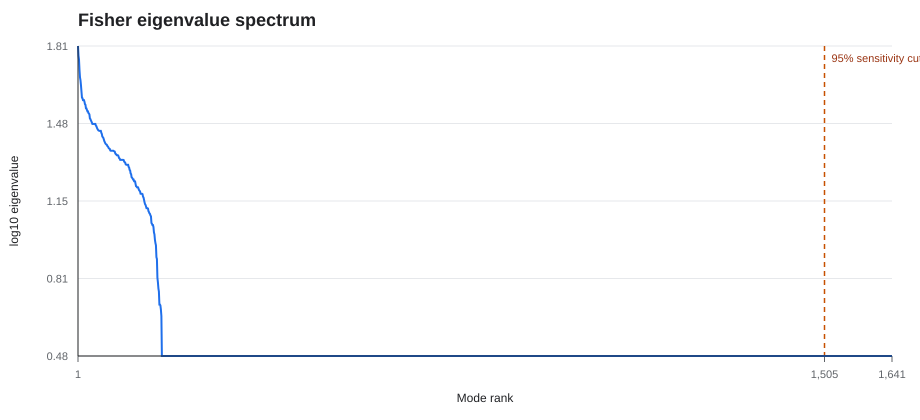

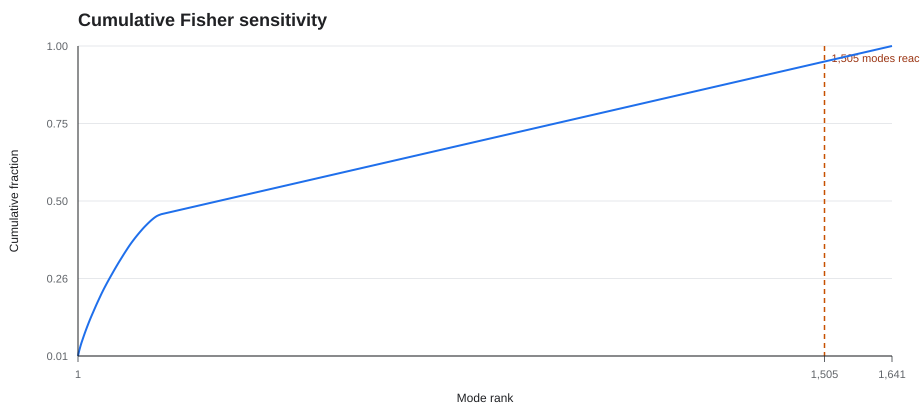

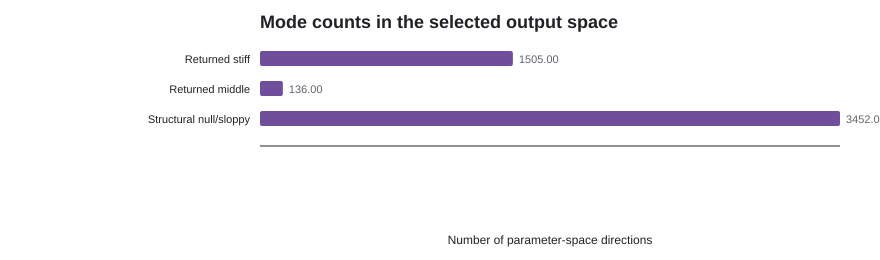

In [10]:
stiff_cut = int((mode_table["classification"] == "stiff").sum())

eigen_spectrum_path = line_chart_svg(
    mode_table["mode"],
    mode_table["log10_eigenvalue"],
    "Fisher eigenvalue spectrum",
    "Mode rank",
    "log10 eigenvalue",
    "fisher_eigenvalue_spectrum.svg",
    vertical_mark=stiff_cut,
    mark_label=f"95% sensitivity cutoff: {stiff_cut:,} stiff modes",
)

cumulative_path = line_chart_svg(
    mode_table["mode"],
    mode_table["cumulative_fraction"],
    "Cumulative Fisher sensitivity",
    "Mode rank",
    "Cumulative fraction",
    "cumulative_fisher_sensitivity.svg",
    vertical_mark=stiff_cut,
    mark_label=f"{stiff_cut:,} modes reach 95%",
)

mode_count_labels = ["Returned stiff", "Returned middle", "Structural null/sloppy"]
mode_count_values = [
    int((mode_table["classification"] == "stiff").sum()),
    int((mode_table["classification"] == "middle").sum()),
    int(structural_null_modes),
]
mode_counts_path = horizontal_bar_svg(
    mode_count_labels,
    mode_count_values,
    "Mode counts in the selected output space",
    "Number of parameter-space directions",
    "mode_count_summary.svg",
    color="#6f4e9b",
    width=880,
    row_h=30,
)

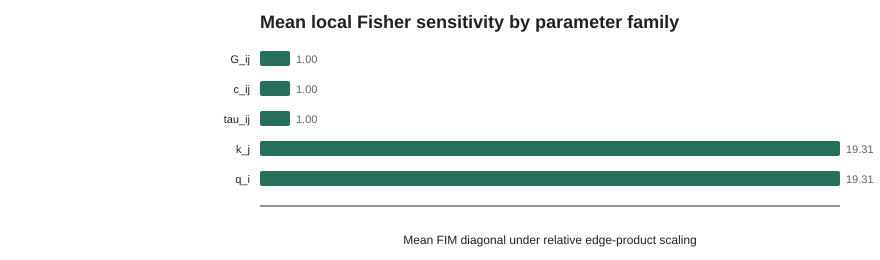

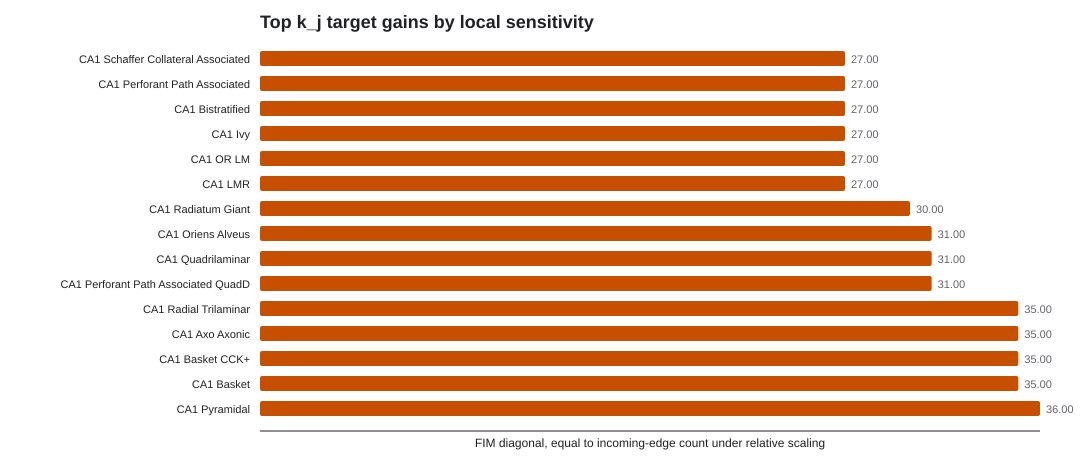

,figure,path
0,Fisher eigenvalue spectrum,C:\Users\ranic\Documents\Codex\2026-10-08\deve...
1,Cumulative Fisher sensitivity,C:\Users\ranic\Documents\Codex\2026-10-08\deve...
2,Mode count summary,C:\Users\ranic\Documents\Codex\2026-10-08\deve...
3,Family mean FIM diagonal,C:\Users\ranic\Documents\Codex\2026-10-08\deve...
4,Top k_j sensitivity,C:\Users\ranic\Documents\Codex\2026-10-08\deve...


In [11]:
family_plot = family_summary.sort_values("mean_fim_diagonal", ascending=True)
family_sensitivity_path = horizontal_bar_svg(
    family_plot["family"],
    family_plot["mean_fim_diagonal"].astype(float),
    "Mean local Fisher sensitivity by parameter family",
    "Mean FIM diagonal under relative edge-product scaling",
    "family_mean_fim_diagonal.svg",
    color="#256f5b",
    width=880,
    row_h=30,
)

top_k = k_scores.sort_values("fim_diagonal", ascending=False).head(15).sort_values("fim_diagonal", ascending=True)
kj_top_path = horizontal_bar_svg(
    top_k["post_neuron"],
    top_k["fim_diagonal"].astype(float),
    "Top k_j target gains by local sensitivity",
    "FIM diagonal, equal to incoming-edge count under relative scaling",
    "top_kj_sensitivity.svg",
    color="#c75000",
    width=1080,
    row_h=25,
)

figure_paths = pd.DataFrame({
    "figure": [
        "Fisher eigenvalue spectrum",
        "Cumulative Fisher sensitivity",
        "Mode count summary",
        "Family mean FIM diagonal",
        "Top k_j sensitivity",
    ],
    "path": [
        str(eigen_spectrum_path),
        str(cumulative_path),
        str(mode_counts_path),
        str(family_sensitivity_path),
        str(kj_top_path),
    ],
})
display(figure_paths)

## Save Results

In [12]:
mode_table.to_csv(OUTPUT_DIR / "ascoli_mode_table.csv", index=False)
parameter_scores.to_csv(OUTPUT_DIR / "ascoli_parameter_scores.csv", index=False)
k_scores.to_csv(OUTPUT_DIR / "ascoli_kj_sensitivity_scores.csv", index=False)
k_profiles.to_csv(OUTPUT_DIR / "ascoli_kj_profile_curves.csv", index=False)
family_summary.to_csv(OUTPUT_DIR / "ascoli_family_summary.csv", index=False)
family_matrix.to_csv(OUTPUT_DIR / "ascoli_mode_family_loadings.csv", index=False)
figure_paths.to_csv(OUTPUT_DIR / "ascoli_visualization_paths.csv", index=False)

print("Saved result tables to", OUTPUT_DIR)

Saved result tables to C:\Users\ranic\Documents\Codex\2026-10-08\develop-a-workflow-or-ipynb-that-2\outputs


## Interpretation Notes

- If many structural null modes are present, that is expected: there are more parameters than edge-level observables.
- Log transformations make the product additive, but they reveal rather than remove compensating directions.
- A tensor/family view helps interpret the mode structure, but independent observables or priors are still needed to separate factors that only appear through the same product.
- `k_j` sensitivity in this notebook is target-gain sensitivity: each `k_j` affects all incoming edges for postsynaptic neuron type `j`.